###<font color='red'>Made by Anton Rudchenko for ParKinSim (Parallel Kinematic Simulation) project.</font>


This is an inital attemp to create a neural network model using ChatGPT for solving reverse kinematics problem based on a dataset acquired from a simulation of the Pentapod. The ChatGPT is used to complete the task fast and get general understanding on how this approach performs on this problem.

In [ ]:
#@title <font color='yellow'>Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

##<font color='yellow'>Importing and preprocessing data collected from solving direct kinematics in simulation.

In [ ]:
data = pd.read_csv('filtered_first.csv').drop_duplicates()
print(data)

         L1    L2    L3    L4    L5       X       Y       Z     RX     RY     RZ
0      14.0  16.0  15.0  15.0  15.0   6.225 -36.857 -29.095  0.255  0.039  0.045
1      13.0  16.0  15.0  15.0  15.0   6.911 -39.529 -26.396  0.274  0.043  0.048
2      12.0  16.0  15.0  15.0  15.0   7.764 -43.206 -23.034  0.301  0.047  0.052
3      11.0  16.0  15.0  15.0  15.0   8.963 -48.874 -18.280  0.342  0.054  0.058
4      11.0  15.0  15.0  15.0  15.0   7.614 -56.939 -13.149  0.400  0.042  0.046
...     ...   ...   ...   ...   ...     ...     ...     ...    ...    ...    ...
17572   3.0   4.0  39.0  23.0  39.0 -27.902  82.199 -40.218 -0.450 -0.207 -0.089
17573   3.0   4.0  39.0  27.0  39.0 -32.052  87.061 -36.371 -0.506 -0.244 -0.094
17574   3.0   4.0  39.0  31.0  39.0 -35.923  91.424 -32.105 -0.561 -0.279 -0.094
17575   3.0   4.0  39.0  33.0  39.0 -37.765  93.431 -29.821 -0.589 -0.296 -0.093
17576   3.0   4.0  39.0  35.0  39.0 -39.549  95.328 -27.440 -0.616 -0.314 -0.091

[17577 rows x 11 columns]


## <font color='orange'>Fully connected feedforward neural network (FCNN) model definition

In [ ]:
# Split input (X, Y, Z, RX, RY, RZ) and output (L1, L2, L3, L4, L5)
X = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']].values
y = data[['L1', 'L2', 'L3', 'L4', 'L5']].values

# Normalize the data
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Split into training, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y_scaled, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Build the neural network model
model = Sequential([
    Dense(128, activation='relu', input_shape=(6,)),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(5, activation='linear')
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Evaluate the model
loss, mae = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {loss:.4f}, Test MAE: {mae:.4f}")

# Predictions
y_pred = model.predict(X_test)

# Reverse normalization for visualization
y_test_original = scaler_y.inverse_transform(y_test)
y_pred_original = scaler_y.inverse_transform(y_pred)

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


385/385 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0862 - mae: 0.2193 - val_loss: 0.0173 - val_mae: 0.0970
Epoch 2/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0199 - mae: 0.1070 - val_loss: 0.0058 - val_mae: 0.0599
Epoch 3/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0108 - mae: 0.0797 - val_loss: 0.0022 - val_mae: 0.0366
Epoch 4/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0084 - mae: 0.0703 - val_loss: 0.0015 - val_mae: 0.0298
Epoch 5/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0072 - mae: 0.0644 - val_loss: 0.0016 - val_mae: 0.0303
Epoch 6/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0067 - mae: 0.0624 - val_loss: 0.0018 - val_mae: 0.0329
Epoch 7/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0062 - mae: 0.0597 - val_loss: 0.0016 - val_mae: 0.0312
Epoch 8/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0057 - mae: 0.0575 - val_loss: 0.0016 - val_mae: 0.0320
Epoch 9/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss:

In [ ]:
# Calculate metrics
mse = mean_squared_error(y_test_original, y_pred_original)
mae = mean_absolute_error(y_test_original, y_pred_original)
r2 = r2_score(y_test_original, y_pred_original)

# Print the metrics
print("\nAccuracy Metrics:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")



Accuracy Metrics:
Mean Squared Error (MSE): 6.7400
Mean Absolute Error (MAE): 2.0266
R-squared (R2): 0.9903


R-squared measures how well the model explains the variance in the data.
* R^2=1: Perfect fit.
* 𝑅^2=0: Predictions are as good as simply using the mean of the data.

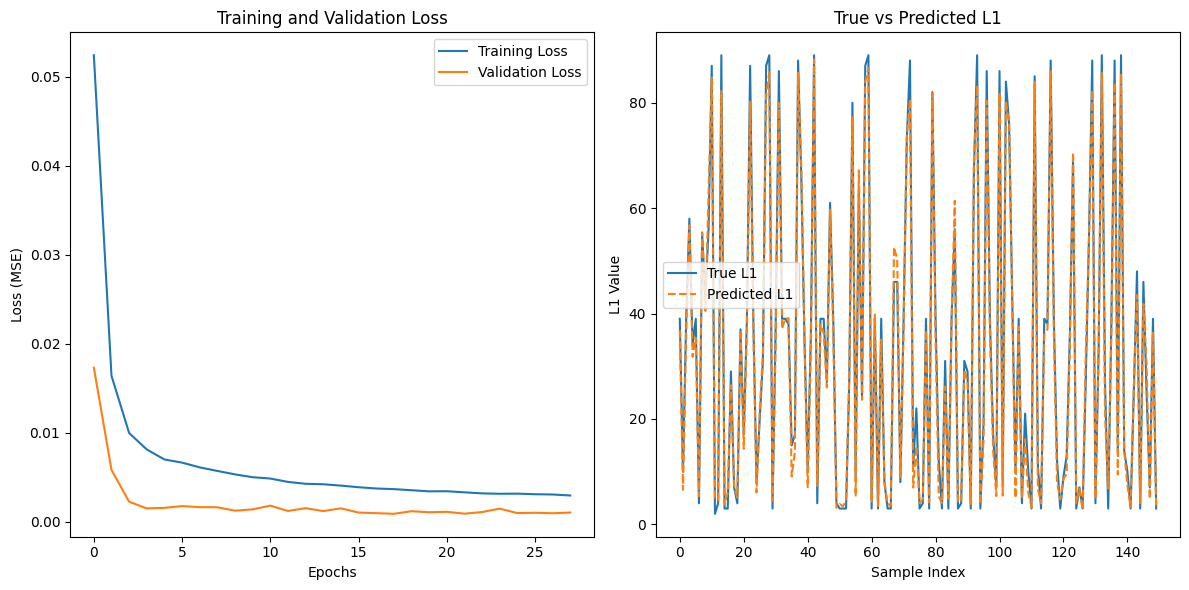

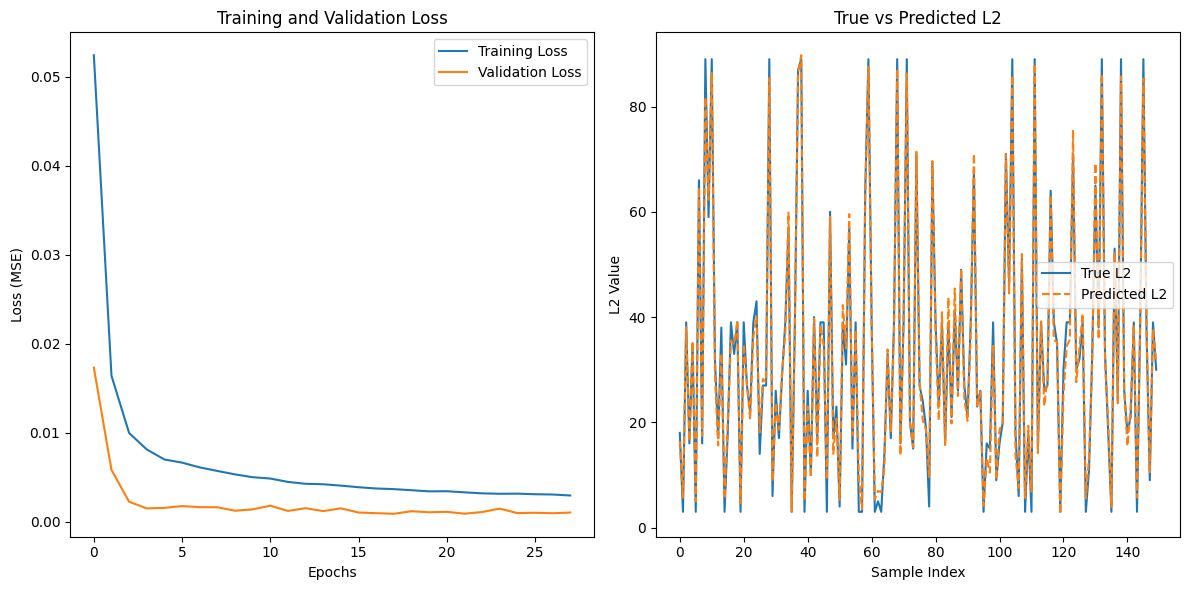

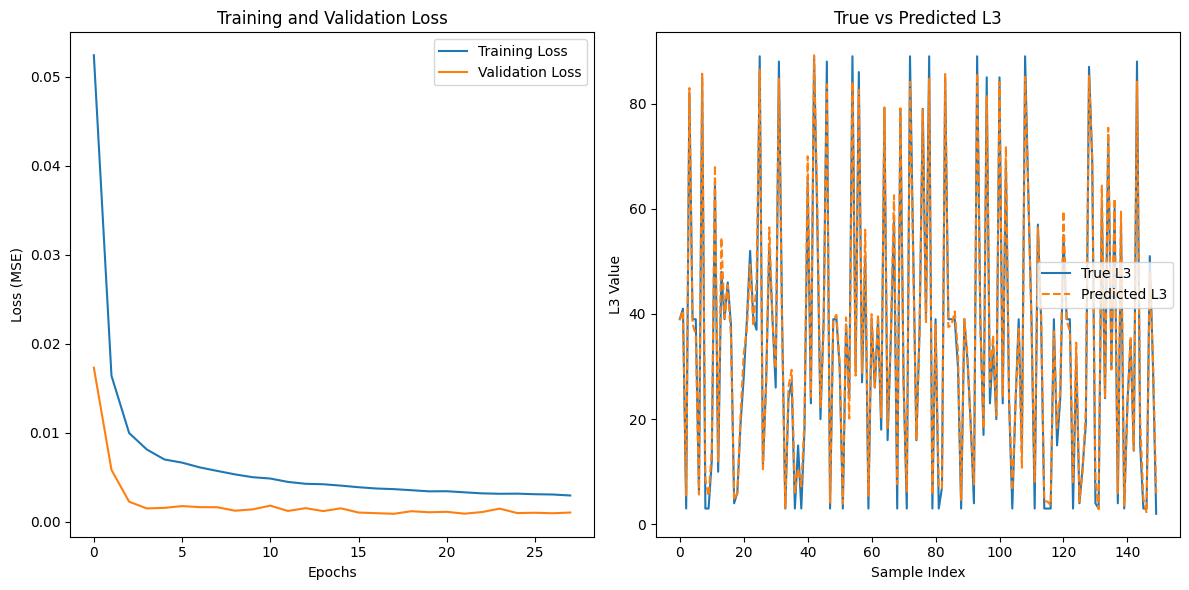

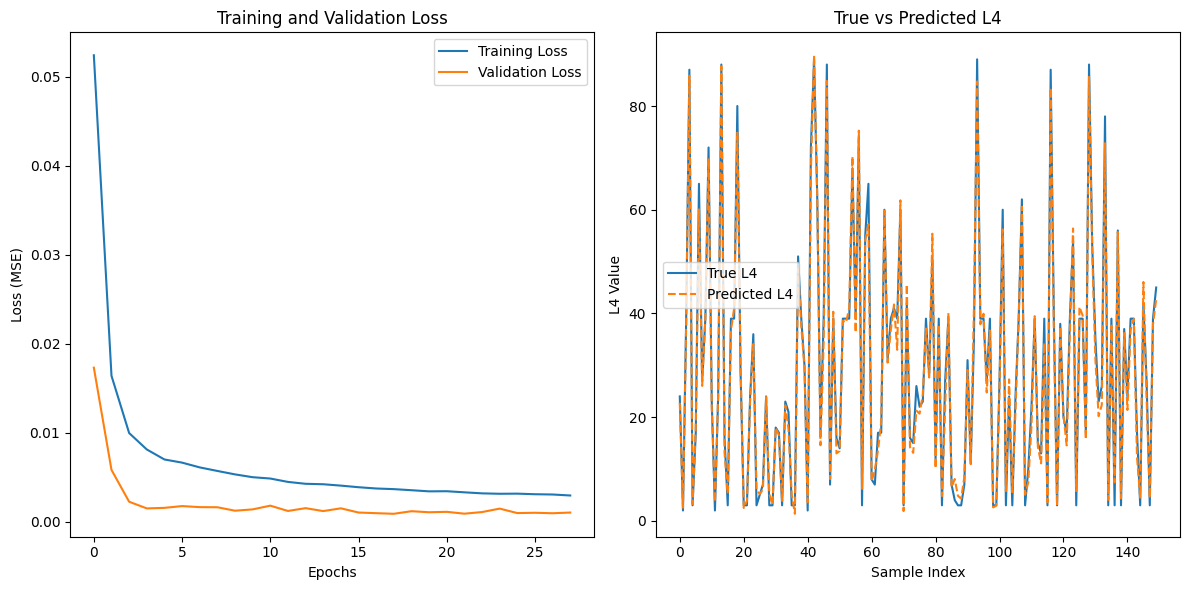

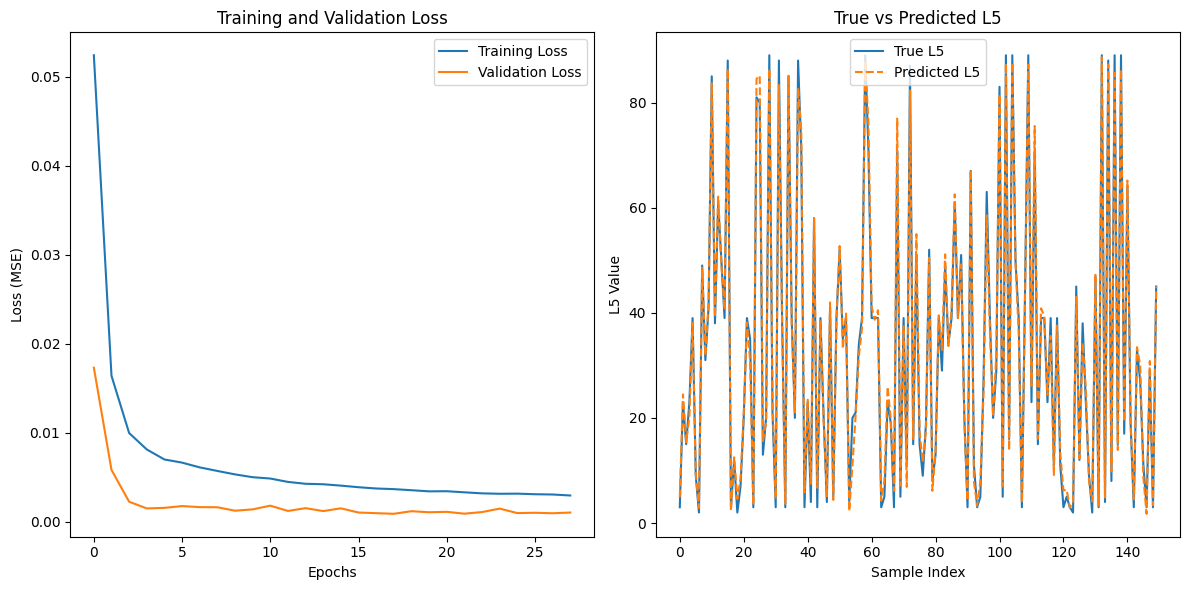

In [ ]:
#@title Visualization

def plot_metrics(l, range_max):
    plt.figure(figsize=(12, 6))

    # Plot training and validation loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (MSE)')
    plt.title('Training and Validation Loss')
    plt.legend()

    # Compare true vs predicted values for a single actuator (e.g., L1)
    plt.subplot(1, 2, 2)
    plt.plot(y_test_original[:range_max, l], label=f'True L{l+1}')
    plt.plot(y_pred_original[:range_max, l], label=f'Predicted L{l+1}', linestyle='dashed')
    plt.xlabel('Sample Index')
    plt.ylabel(f'L{l+1} Value')
    plt.title(f'True vs Predicted L{l+1}')
    plt.legend()

    plt.tight_layout()
    plt.show()

for i in range(0, 5):
    plot_metrics(i, 150)

# Save the model
model.save("reverse_kinematics_model.h5")

## <font color='orange'>Retraining

In [ ]:
#@title function for further predictions

def make_prediction(desired):
    # Load the saved model
    #model = load_model("reverse_kinematics_model.h5")

    # Define the input values
    xyzrxryrz = np.array([desired])  # Make sure it's a 2D array (1, 6)

    # Normalize the input using the same scaler used during training
    xyzrxryrz_scaled = scaler_X.transform(xyzrxryrz)  # Ensure scaler_X is available

    # Make the prediction
    prediction_scaled = model.predict(xyzrxryrz_scaled)

    # Reverse the normalization to get the original scale
    prediction = scaler_y.inverse_transform(prediction_scaled)

    # Print the result
    res = prediction[0].tolist()
    print("Predicted actuator lengths (L1, L2, L3, L4, L5):", res)
    return res

    #return prediction[0]

desired = [0, 0, 0, 0, 0, 0]

make_prediction(desired)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Predicted actuator lengths (L1, L2, L3, L4, L5): [-0.38050341606140137, 30.63275909423828, 16.9942684173584, 33.514495849609375, 20.357038497924805]


[-0.38050341606140137,
 30.63275909423828,
 16.9942684173584,
 33.514495849609375,
 20.357038497924805]

In [ ]:
# Enriching data

# Format: [[X, Y, Z, RX, RY, RZ, L1, L2, L3, L4, L5]]
new_data = [
    [4.97, 23.7, 16.19, 29.49, 14.02, -3.295, 17.34, -30.191, -0.148, -0.03, -0.015],
    [5.73, 25.45, 21.19, 31.29, 21.13, -9.528, 58.546, -31.303, -0.429, -0.062, -0.003],
    [5.05, 20.07, 19.91, 26.63, 20.63, -11.942, 36.745, -35.493, -0.246, -0.079, -0.022],
    [4.46, 20.42, 18.12, 31.61, 19.42, -19.818, 38.005, -31.584, -0.275, -0.137, -0.041],
    [1.72, 21.01, 17.9, 25.11, 25.05, -21.556, 41.204, -31.9, -0.265, -0.122, -0.008],
    [3.36, 19.3, 18.23, 23.51, 25.6, -22.751, 37.311, -34.743, -0.23, -0.13, -0.017],
    [3.48, 24.57, 12.6, 26.34, 18.26, -13.284, 12.278, -28.204, -0.102, -0.07, -0.001],
    [0.95, 30.65, 15.47, 31.0, 21.54, -12.457, 53.817, -23.713, -0.406, -0.057, 0.028],
    [0.59, 25.12, 18.86, 16.89, 22.18, 7.513, 25.108, -31.651, -0.144, 0.076, 0.073],
    [0.46, 28.5, 16.54, 22.6, 21.83, -1.141, 37.005, -28.958, -0.254, 0.023, 0.05],
    [1.67, 34.57, 13.08, 28.16, 17.26, 3.237, 34.499, -24.053, -0.284, 0.051, 0.05],
    [1.33, 26.83, 15.61, 19.12, 24.44, -6.071, 31.702, -31.75, -0.201, 0.002, 0.059],
    [0.53, 24.51, 15.63, 26.26, 18.09, -6.015, 19.866, -26.976, -0.143, -0.03, 0.008],
    [0.53, 28.47, 13.99, 23.39, 21.52, -6.321, 28.92, -27.83, -0.204, -0.008, 0.046],
    [0.54, 23.54, 18.29, 20.29, 22.03, -1.772, 27.735, -31.457, -0.167, 0.009, 0.037],
    [0.71, 27.82, 16.57, 14.37, 22.45, 11.893, 16.669, -29.703, -0.092, 0.117, 0.111],
    [0.15, 25.42, 16.23, 15.72, 23.89, 1.018, 18.824, -30.546, -0.098, 0.045, 0.079],
    [0.15, 30.76, 15.78, 24.18, 19.86, 3.123, 35.517, -26.555, -0.258, 0.049, 0.053],
    [1.65, 30.97, 17.79, 23.82, 21.58, 2.759, 47.547, -28.62, -0.34, 0.05, 0.053],
    [1.52, 28.47, 17.69, 27.49, 16.98, 3.974, 36.031, -27.562, -0.27, 0.034, 0.024],
    [2.36, 27.98, 14.74, 24.96, 17.58, 0.896, 21.43, -28.255, -0.166, 0.024, 0.037]
]

In [ ]:
#@title Retraining function and run


def retrain_model(new_data):
    """
    Retrain the model with new data provided in the format:
    [L1, L2, L3, L4, L5, X, Y, Z, RX, RY, RZ].
    :param new_data: List of lists, where each inner list is formatted as above.
    """
    global X_train, y_train  # Ensure access to existing training data

    if not new_data:
        print("No new data provided for retraining.")
        return

    # Convert new data to numpy array
    new_data_array = np.array(new_data)

    # Split new data into inputs and outputs
    y_new = new_data_array[:, :5]  # Actuator lengths (L1, L2, L3, L4, L5)
    X_new = new_data_array[:, 5:]  # Position and orientation (X, Y, Z, RX, RY, RZ)

    # Normalize the new data
    X_new_scaled = scaler_X.transform(X_new)
    y_new_scaled = scaler_y.transform(y_new)

    # Combine new data with existing training data
    X_combined = np.vstack([X_train, X_new_scaled])
    y_combined = np.vstack([y_train, y_new_scaled])

    # Retrain the model with the combined dataset
    model.fit(
        X_combined, y_combined,
        validation_data=(X_val, y_val),
        epochs=50,  # Fewer epochs for fine-tuning
        batch_size=32,
        verbose=1
    )

    # Save the updated model
    model.save("reverse_kinematics_model_updated.h5")
    print("Model retrained and saved as 'reverse_kinematics_model_updated.h5'.")

# Retrain the model with the new data
retrain_model(new_data[-1:])

Epoch 1/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0037 - mae: 0.0462 - val_loss: 0.0010 - val_mae: 0.0244
Epoch 2/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0034 - mae: 0.0446 - val_loss: 0.0012 - val_mae: 0.0265
Epoch 3/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0034 - mae: 0.0441 - val_loss: 0.0010 - val_mae: 0.0247
Epoch 4/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0034 - mae: 0.0438 - val_loss: 0.0010 - val_mae: 0.0250
Epoch 5/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0033 - mae: 0.0436 - val_loss: 0.0011 - val_mae: 0.0253
Epoch 6/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0033 - mae: 0.0432 - val_loss: 0.0010 - val_mae: 0.0245
Epoch 7/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0030 - mae: 0.0418 - val_loss: 0.0010 - val_mae: 0.0253
Epoch 8/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0030 - mae: 0.0415 - val_loss: 9.5860e-04 - val_mae: 0.0239
Epoch 9/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 

Model retrained and saved as 'reverse_kinematics_model_updated.h5'.


In [ ]:
# Attempting to predict the desired pose
import time

start = time.time()
desired = [0, 0, 0, 0, 0, 0]

make_prediction(desired)
end = time.time()

print(end - start)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Predicted actuator lengths (L1, L2, L3, L4, L5): [-0.9607893824577332, 23.05860710144043, 17.00395965576172, 32.70505905151367, 17.225984573364258]
0.06686019897460938


## <font color='orange'>Testing on filtered dataset (linear actuators)


The initial dataset was filtered by distance between datapoints (2mm)

In [ ]:
#@title plotting function
# ChatGPT made it for me ;3

import matplotlib.pyplot as plt

def plot_comparison(actual, predicted, labels=['X', 'Y', 'Z', 'Rx', 'Ry', 'Rz']):
    """
    Plot a comparison of actual vs. predicted values for each parameter.

    Parameters:
    - actual: List of actual values for each parameter (list of lists).
    - predicted: List of predicted values for each parameter (list of lists).
    - labels: Labels for each parameter.
    """
    # Check if the lists have the same length
    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted lists must have the same length")

    # Extract individual parameters (e.g., X, Y, Z, Rx, Ry, Rz)
    actual = list(zip(*actual))  # Transpose to separate parameters
    predicted = list(zip(*predicted))

    # Check if labels match the number of parameters
    if len(labels) != len(actual):
        raise ValueError("Number of labels must match the number of parameters in actual/predicted data.")

    # Determine grid size for subplots
    num_plots = len(labels)
    cols = 3  # Fixed number of columns (can be adjusted)
    rows = (num_plots + cols - 1) // cols  # Calculate required rows

    # Create subplots dynamically
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
    axes = axes.flatten()  # Flatten axes for easy indexing

    for i, ax in enumerate(axes):
        if i < num_plots:  # Plot only if there's data
            # Filter data to replace `999.0` with None
            actual_filtered = [a if a != 999.0 else None for a in actual[i]]
            predicted_filtered = [p if p != 999.0 else None for p in predicted[i]]

            # Plot actual and predicted values
            ax.plot(range(len(actual_filtered)), actual_filtered, label='Actual', marker='o', linestyle='-', alpha=0.7)
            ax.plot(range(len(predicted_filtered)), predicted_filtered, label='Predicted', marker='x', linestyle='--', alpha=0.7)

            # Add labels, title, and legend
            ax.set_title(f'Comparison for {labels[i]}')
            ax.set_xlabel('Index')
            ax.set_ylabel(labels[i])
            ax.legend()
            ax.grid(True)
        else:
            # Hide unused subplots
            ax.axis('off')

    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()


In [ ]:
data_check_filtered = pd.read_csv('filtered_second.csv').drop_duplicates()
print(data)

         L1    L2    L3    L4    L5       X       Y       Z     RX     RY     RZ
0      14.0  16.0  15.0  15.0  15.0   6.225 -36.857 -29.095  0.255  0.039  0.045
1      13.0  16.0  15.0  15.0  15.0   6.911 -39.529 -26.396  0.274  0.043  0.048
2      12.0  16.0  15.0  15.0  15.0   7.764 -43.206 -23.034  0.301  0.047  0.052
3      11.0  16.0  15.0  15.0  15.0   8.963 -48.874 -18.280  0.342  0.054  0.058
4      11.0  15.0  15.0  15.0  15.0   7.614 -56.939 -13.149  0.400  0.042  0.046
...     ...   ...   ...   ...   ...     ...     ...     ...    ...    ...    ...
17572   3.0   4.0  39.0  23.0  39.0 -27.902  82.199 -40.218 -0.450 -0.207 -0.089
17573   3.0   4.0  39.0  27.0  39.0 -32.052  87.061 -36.371 -0.506 -0.244 -0.094
17574   3.0   4.0  39.0  31.0  39.0 -35.923  91.424 -32.105 -0.561 -0.279 -0.094
17575   3.0   4.0  39.0  33.0  39.0 -37.765  93.431 -29.821 -0.589 -0.296 -0.093
17576   3.0   4.0  39.0  35.0  39.0 -39.549  95.328 -27.440 -0.616 -0.314 -0.091

[17577 rows x 11 columns]


In [ ]:
X = data_check_filtered[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']].values[:700]
y = data_check_filtered[['L1', 'L2', 'L3', 'L4', 'L5']].values[:700]

#print(X)
#print(y)

In [ ]:
res = []
for i in X:
    y_pred = make_prediction(i)
    res.append(y_pred)

res = np.array(res)

#print(res)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Predicted actuator lengths (L1, L2, L3, L4, L5): [23.209381103515625, 7.251374244689941, 80.5985336303711, 34.33372497558594, 9.209494590759277]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Predicted actuator lengths (L1, L2, L3, L4, L5): [3.527362585067749, 28.52155876159668, 37.0850715637207, 37.475467681884766, 37.905433654785156]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Predicted actuator lengths (L1, L2, L3, L4, L5): [3.3840649127960205, 28.39017677307129, 36.917686462402344, 38.03666687011719, 37.824649810791016]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Predicted actuator lengths (L1, L2, L3, L4, L5): [3.1861512660980225, 28.16153335571289, 36.66743469238281, 39.11166763305664, 37.33517074584961]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Predicted actuator lengths (L1, L2, L3, L4, L5): [47.20137023925781, 7.993404388427734, 80.51323699951172, 36.43037414550781, 7.774651527404785]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Predicted actuator lengths (L1, L2, L3, L4

In [ ]:
# writing predicted configurations into a text file for further validation in simulation
with open('predictions.txt', 'w') as writefile:
    for i in res:
        #print(i)
        writefile.write(f'{i[0]}, {i[1]}, {i[2]}, {i[3]}, {i[4]}\n')


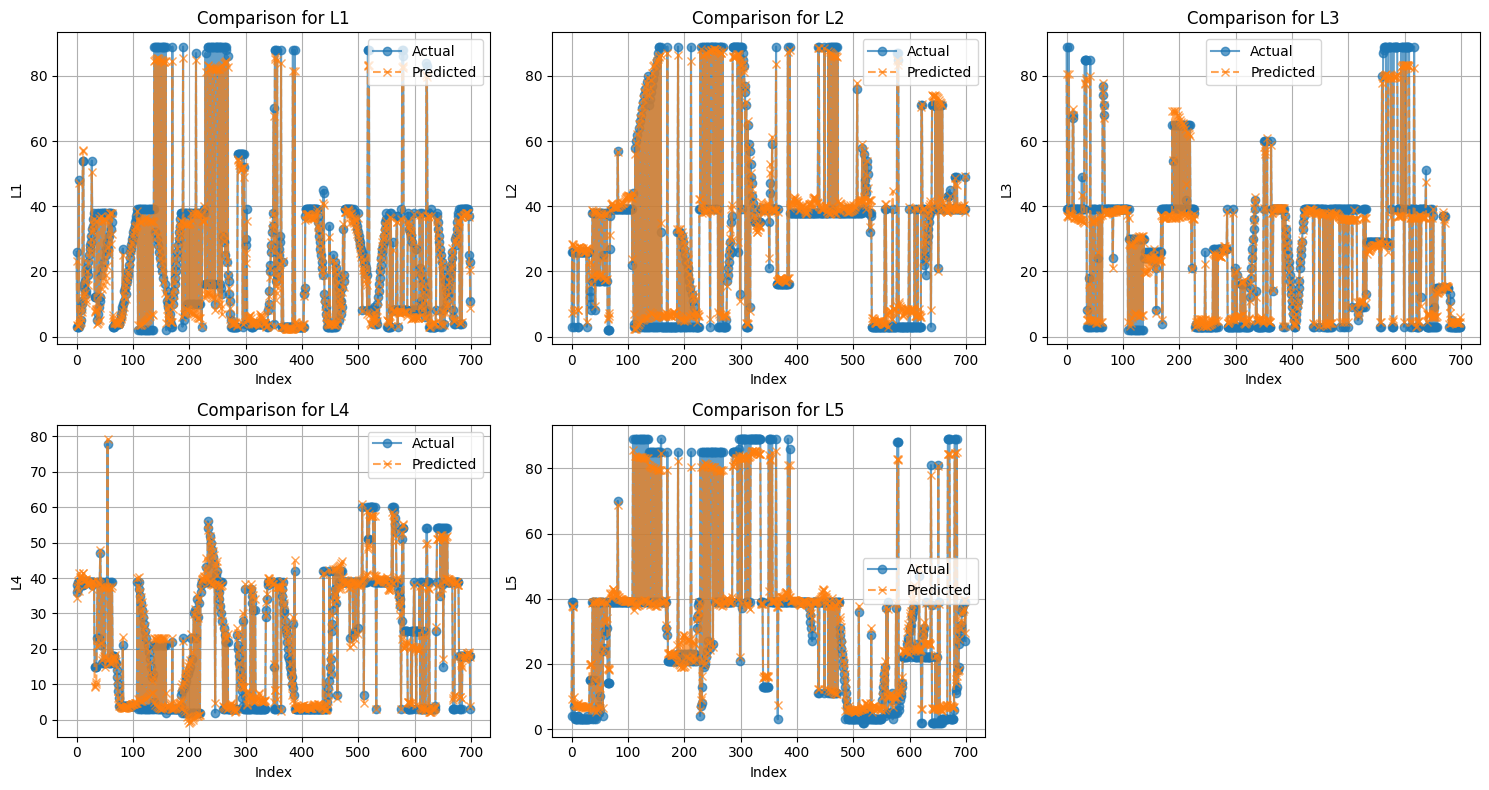

In [ ]:
plot_comparison(y, res, labels=['L1', 'L2', 'L3', 'L4', 'L5'])

In [ ]:
# Calculate metrics
mse = mean_squared_error(res, y)
mae = mean_absolute_error(res, y)
r2 = r2_score(res, y)

# Print the metrics
print("\nAccuracy Metrics:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")


Accuracy Metrics:
Mean Squared Error (MSE): 6.8277
Mean Absolute Error (MAE): 2.0199
R-squared (R2): 0.9857


## <font color='orange'>Testing on filtered dataset (pose)

In [ ]:
# Importing results check in simulation
with open("tested.txt", 'r') as file:
    res = [[float(i) for i in x.strip().split(',')] for x in file.readlines()]

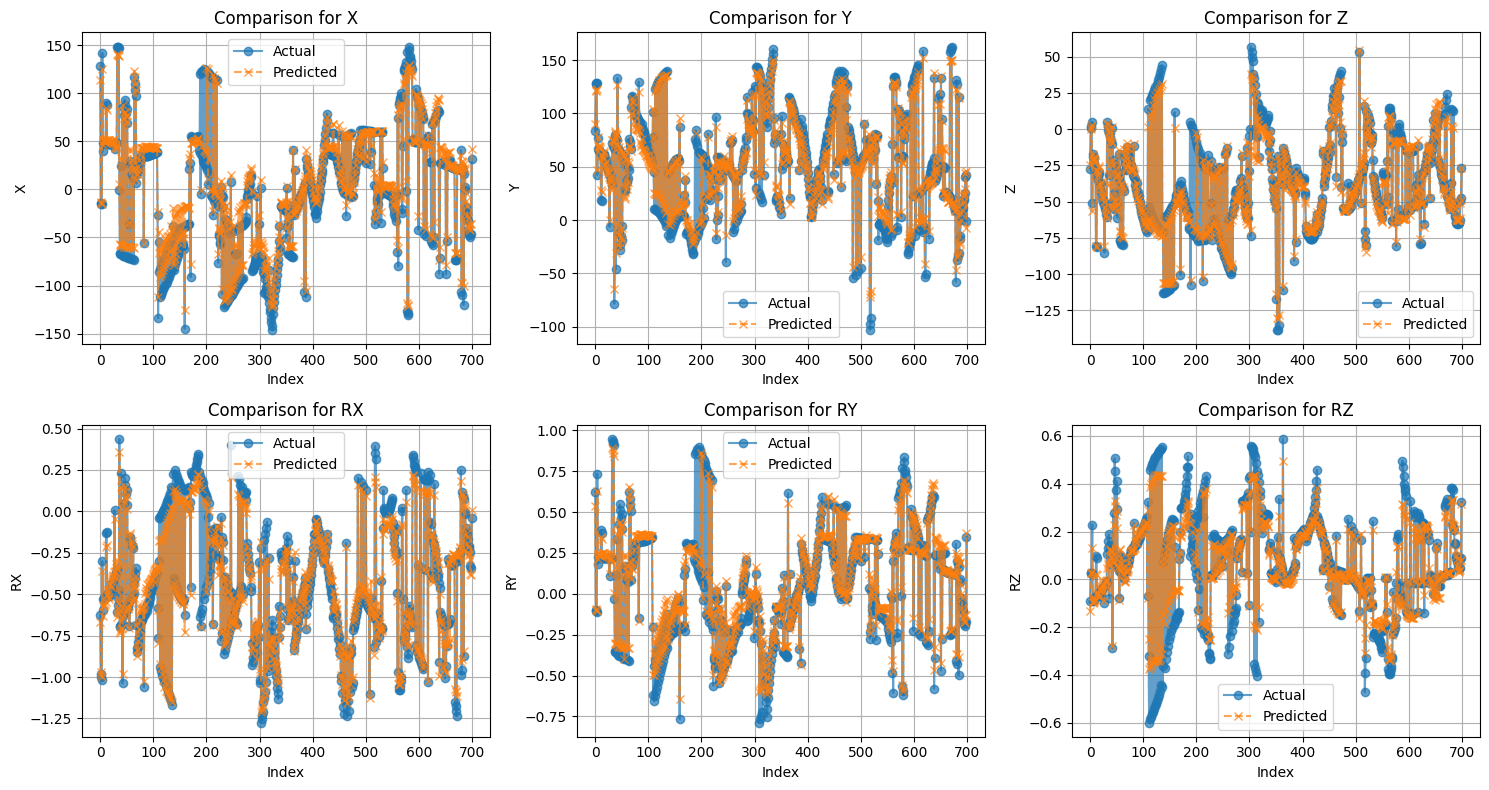

In [ ]:
plot_comparison(X, res, labels=['X', 'Y', 'Z', 'RX', 'RY', 'RZ'])

In [ ]:
#@title There are failed simulations which written as [999, 999, 999, 999, 999, 999]; lets count how many of those:

count = sum(1 for sublist in res if all(item == 999 for item in sublist))
print(f'There are {count} failed simulations, which is {(count/len(res))*100}%')

There are 14 failed simulations, which is 2.0%


In [ ]:
predicted = np.array(res)
actual = X

## <font color='red'>Conclusion:

The initial dataset from simulation was filtered based on distance beteween points, removed points were later used to test the model's performance and it's results can be seen next as "Test on filtered dataset".

<font color='red'>The metrics are made comparing actual configurations with predicted ones, not poses!</font>

Test accuracy:

* Mean Squared Error (MSE): 8.3426
* Mean Absolute Error (MAE): 2.2995
* R-squared (R2): 0.9902

Test on filtered dataset:

* Mean Squared Error (MSE): 8.8050
* Mean Absolute Error (MAE): 2.3409
* R-squared (R2): 0.9878

All in all, the accuracy is good enough when it comes to pure numbers, and the model learns the patterns in the data pretty well, what can be seen on plots above.

P.S. - only first 700 data entries as coolab handles poorly an 1800 dataset.

## <font color='red'>Pose:

As can be seen on the plots, main pattern is predicted on all of the lables relatively precisely, but RZ! Possibly because it's pattern is not obvious due to mechanical restriction of the system.